# Lab 2 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab02.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [4]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import lab02

X, y = lab02.load_data('../data/clinic_noshow.csv')
results = lab02.run_experiment(X, y)
results

{'baseline': {'accuracy': 0.65, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0},
 'logreg': {'accuracy': 0.6917,
  'precision': 0.5735,
  'recall': 0.4643,
  'f1': 0.5132},
 'knn': {'accuracy': 0.6917,
  'precision': 0.5806,
  'recall': 0.4286,
  'f1': 0.4932}}

## Plot 1 — Class balance

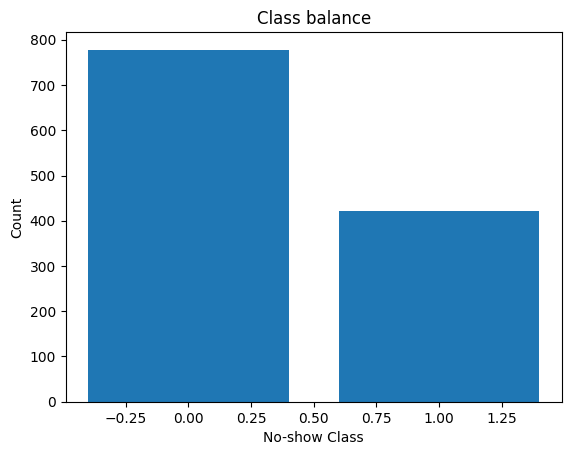

In [6]:
# ============ TODO (Plot 1) ============
# Bar chart of y.value_counts(). Title + axis labels.
# =======================================

counts = y.value_counts()

# bar chart
plt.bar(counts.index, counts.values)
plt.xlabel("No-show Class")
plt.ylabel("Count")
plt.title("Class balance")

plt.savefig("fig1.png", dpi=150)

plt.show()


## Plot 2 — One feature, split by class

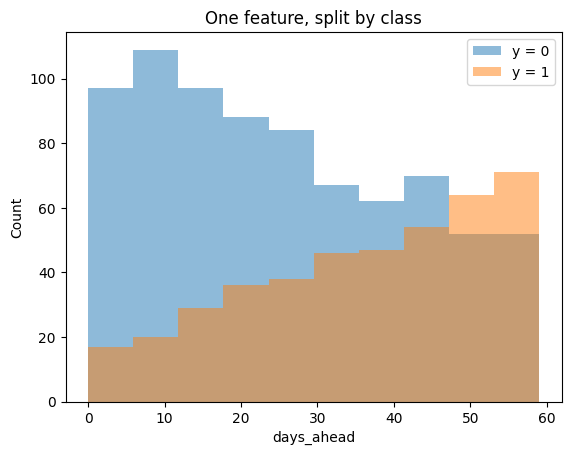

In [9]:
# ============ TODO (Plot 2) ============
# Overlaid histograms of X['days_ahead'] for y==0 vs y==1 (alpha=0.5, legend).
# Comment: does this feature separate the classes?
# days_ahead shows some class separation, but the distributions still overlap substantially.
# =======================================

# X['days_ahead']를 0/1 그룹으로 나누고
days_0 = X.loc[y == 0, "days_ahead"]
days_1 = X.loc[y == 1, "days_ahead"]

# histogram 겹쳐서 그리고
plt.hist(days_0, alpha=0.5, label="y = 0")
plt.hist(days_1, alpha=0.5, label="y = 1")

plt.xlabel("days_ahead")
plt.ylabel("Count")
plt.title("One feature, split by class")
plt.legend()

plt.savefig("fig2.png", dpi=150)

plt.show()


## Plot 3 — Model comparison

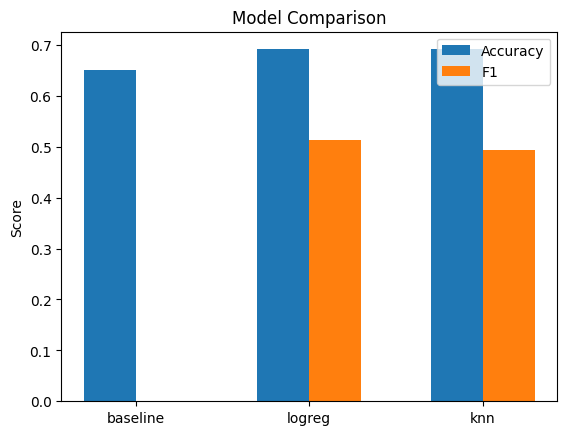

In [15]:
# ============ TODO (Plot 3) ============
# Grouped bar chart: accuracy and f1 for baseline / logreg / knn (use `results`).
# =======================================
import numpy as np

models = ["baseline", "logreg", "knn"]

accuracy = [results[m]["accuracy"] for m in models]
f1 = [results[m]["f1"] for m in models]

# bar 만들기
x = np.arange(len(models))
width = 0.3

# accuracy bar
plt.bar(x - width/2, accuracy, width=width, label="Accuracy")

# f1 bar
plt.bar(x + width/2, f1, width=width, label="F1")

plt.xticks(x, models)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Model Comparison")
plt.legend()

plt.savefig("fig3.png", dpi=150)
plt.show()

